# Tech Challenge Fase 3 - Tratamento de Valores Ausentes
## Estrategias e Pipeline de Missing Values

**Disciplina**: Machine Learning Engineering - Fase 3  
**Instituicao**: FIAP PosTech - AI Engineering & Machine Learning

---

## Indice
1. [Configuracao do Ambiente](#1-configuracao)
2. [Carregamento dos Dados](#2-carregamento)
3. [Analise de Missing Values](#3-analise)
4. [Padroes de Missingness](#4-padroes)
5. [Tratamento de Voos Cancelados](#5-cancelados)
6. [Tratamento de Voos Desviados](#6-desviados)
7. [Imputacao de Horarios](#7-horarios)
8. [Imputacao de Delays](#8-delays)
9. [Pipeline Completo](#9-pipeline)
10. [Salvamento dos Dados Limpos](#10-salvamento)

---

## 1. Configuracao do Ambiente <a id='1-configuracao'></a>

### 1.1 Importacao de Bibliotecas

In [1]:
# Manipulacao de dados
import pandas as pd
import numpy as np
import sys
import os

# Visualizacao
import matplotlib.pyplot as plt
import seaborn as sns

# Adicionar path do projeto
sys.path.append('../src')

# Importar modulos do projeto
from preprocessing.data_loader import load_all_datasets
from preprocessing.missing_values import (
    analyze_missing_values,
    get_missing_patterns,
    handle_all_missing_values,
    calcular_tempo_decorrido,
    calcular_delay
)

# Configuracoes
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.2f}'.format)

# Configuracao de graficos
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')

print("Bibliotecas importadas com sucesso!")
print(f"Pandas: {pd.__version__}")
print(f"NumPy: {np.__version__}")

Bibliotecas importadas com sucesso!
Pandas: 2.1.4
NumPy: 1.26.2


### 1.2 Definicao de Constantes

In [2]:
# Caminhos dos arquivos
DATA_PATH = '../data/raw/'
FLIGHTS_FILE = f'{DATA_PATH}flights.csv'
AIRPORTS_FILE = f'{DATA_PATH}airports.csv'
AIRLINES_FILE = f'{DATA_PATH}airlines.csv'

# Caminho para salvar dados limpos
PROCESSED_DATA_PATH = '../data/processed/'
os.makedirs(PROCESSED_DATA_PATH, exist_ok=True)

# Constantes
DELAY_THRESHOLD = 15
RANDOM_STATE = 42
USE_FULL_DATASET = True  # True = todos os 5.819.080 registros
SAMPLE_SIZE = None if USE_FULL_DATASET else 100000

print("Configuracoes:")
print(f"  - Dataset: {'COMPLETO' if USE_FULL_DATASET else f'AMOSTRA ({SAMPLE_SIZE:,} registros)'}")
print(f"  - Threshold de atraso: {DELAY_THRESHOLD} minutos")

Configuracoes:
  - Dataset: COMPLETO
  - Threshold de atraso: 15 minutos


---
## 2. Carregamento dos Dados <a id='2-carregamento'></a>

In [3]:
print("Carregando datasets...")
print("Isso pode levar alguns minutos para o dataset completo...\n")

df_flights, df_airports, df_airlines = load_all_datasets(
    FLIGHTS_FILE,
    AIRPORTS_FILE,
    AIRLINES_FILE,
    flights_nrows=SAMPLE_SIZE,
    optimize_memory=True,
    verbose=True
)

print(f"\nDados carregados:")
print(f"  - Voos: {len(df_flights):,} registros")
print(f"  - Aeroportos: {len(df_airports)} registros")
print(f"  - Companhias: {len(df_airlines)} registros")

Carregando datasets...
Isso pode levar alguns minutos para o dataset completo...


CARREGANDO TODOS OS DATASETS

CARREGANDO DATASET DE VOOS
Modo: Dataset completo

Dataset carregado com sucesso!
Dimensões: 5,819,079 linhas x 31 colunas
Memória utilizada: 505.53 MB

Carregando dataset de aeroportos...
322 aeroportos carregados!
Memória: 120.03 KB

Carregando dataset de companhias aéreas...
14 companhias aéreas carregadas!
Memória: 2.55 KB

TODOS OS DATASETS CARREGADOS COM SUCESSO!
Memória total utilizada: 505.65 MB


Dados carregados:
  - Voos: 5,819,079 registros
  - Aeroportos: 322 registros
  - Companhias: 14 registros


In [4]:
# Visualizar primeiras linhas
print("Primeiras 5 linhas do dataset de voos:")
display(df_flights.head())

Primeiras 5 linhas do dataset de voos:


,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,DEPARTURE_TIME,DEPARTURE_DELAY,TAXI_OUT,WHEELS_OFF,SCHEDULED_TIME,ELAPSED_TIME,AIR_TIME,DISTANCE,WHEELS_ON,TAXI_IN,SCHEDULED_ARRIVAL,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5.00,2354.00,-11.00,21.00,15.00,205.00,194.00,169.00,1448,404.00,4.00,430.00,408.00,-22.00,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10.00,2.00,-8.00,12.00,14.00,280.00,279.00,263.00,2330,737.00,4.00,750.00,741.00,-9.00,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,1,1,4,US,840,N171US,SFO,CLT,20.00,18.00,-2.00,16.00,34.00,286.00,293.00,266.00,2296,800.00,11.00,806.00,811.00,5.00,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20.00,15.00,-5.00,15.00,30.00,285.00,281.00,258.00,2342,748.00,8.00,805.00,756.00,-9.00,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25.00,24.00,-1.00,11.00,35.00,235.00,215.00,199.00,1448,254.00,5.00,320.00,259.00,-21.00,0,0,NaN,NaN,NaN,NaN,NaN,NaN


---
## 3. Analise de Missing Values <a id='3-analise'></a>

### 3.1 Mapeamento Completo de Valores Ausentes

In [5]:
# Analisar valores ausentes
missing_report = analyze_missing_values(df_flights, verbose=True)

ANALISE DE VALORES AUSENTES

Total de colunas com valores ausentes: 18

                 column  total_missing  percent_missing     dtype  non_null_count  total_count
0   CANCELLATION_REASON        5729195            98.46  category           89884      5819079
1         WEATHER_DELAY        4755640            81.72   float32         1063439      5819079
2   LATE_AIRCRAFT_DELAY        4755640            81.72   float32         1063439      5819079
3         AIRLINE_DELAY        4755640            81.72   float32         1063439      5819079
4        SECURITY_DELAY        4755640            81.72   float32         1063439      5819079
5      AIR_SYSTEM_DELAY        4755640            81.72   float32         1063439      5819079
6          ELAPSED_TIME         105071             1.81   float32         5714008      5819079
7              AIR_TIME         105071             1.81   float32         5714008      5819079
8         ARRIVAL_DELAY         105071             1.81   float32        

In [6]:
# Visualizar o relatorio de missing values
if len(missing_report) > 0:
    print("\nRelatorio detalhado de valores ausentes:")
    display(missing_report.style.background_gradient(
        subset=['percent_missing'], 
        cmap='YlOrRd'
    ))
else:
    print("Nenhum valor ausente encontrado!")


Relatorio detalhado de valores ausentes:


,column,total_missing,percent_missing,dtype,non_null_count,total_count
0,CANCELLATION_REASON,5729195,98.455357,category,89884,5819079
1,WEATHER_DELAY,4755640,81.724960,float32,1063439,5819079
2,LATE_AIRCRAFT_DELAY,4755640,81.724960,float32,1063439,5819079
3,AIRLINE_DELAY,4755640,81.724960,float32,1063439,5819079
4,SECURITY_DELAY,4755640,81.724960,float32,1063439,5819079
5,AIR_SYSTEM_DELAY,4755640,81.724960,float32,1063439,5819079
6,ELAPSED_TIME,105071,1.805629,float32,5714008,5819079
7,AIR_TIME,105071,1.805629,float32,5714008,5819079
8,ARRIVAL_DELAY,105071,1.805629,float32,5714008,5819079
9,ARRIVAL_TIME,92513,1.589822,float32,5726566,5819079


### 3.2 Visualizacao de Missing Values

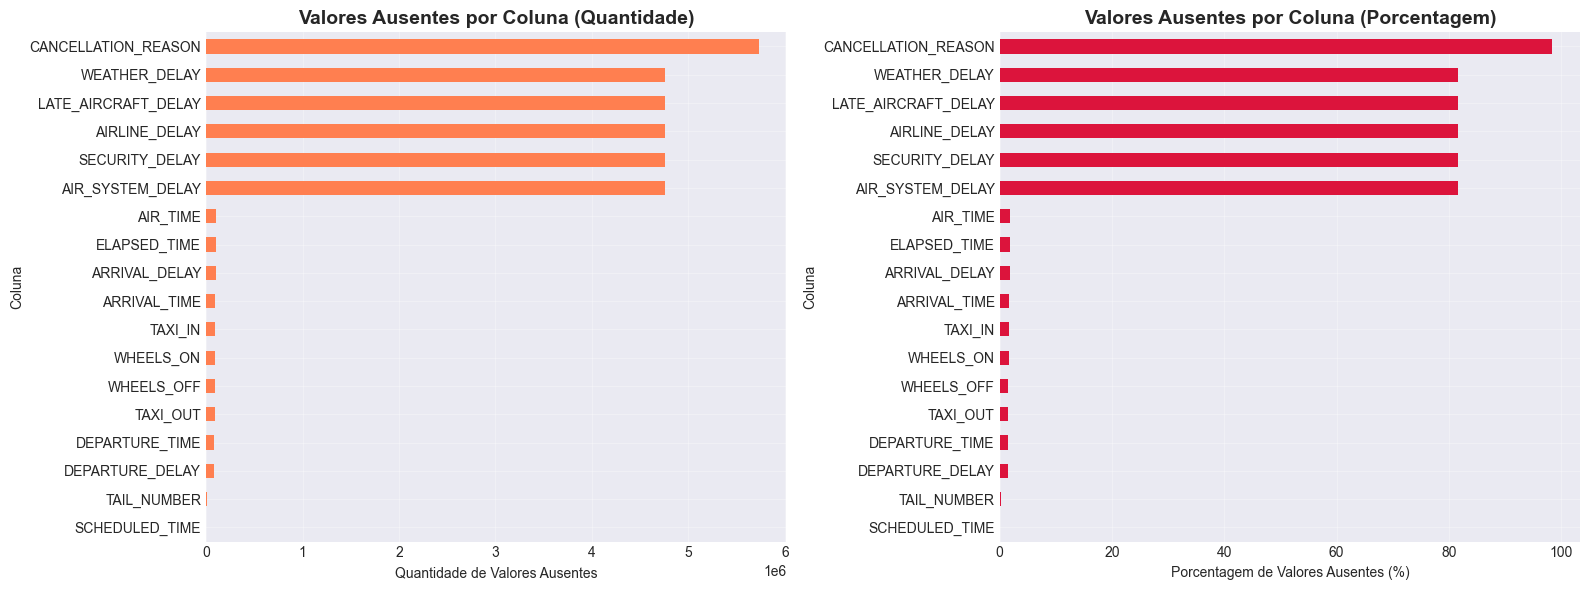

In [7]:
# Grafico de barras de missing values
if len(missing_report) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # Grafico 1: Quantidade absoluta
    missing_report.sort_values('total_missing', ascending=True).plot(
        x='column', 
        y='total_missing', 
        kind='barh', 
        ax=axes[0],
        color='coral',
        legend=False
    )
    axes[0].set_title('Valores Ausentes por Coluna (Quantidade)', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Quantidade de Valores Ausentes')
    axes[0].set_ylabel('Coluna')
    axes[0].grid(True, alpha=0.3)
    
    # Grafico 2: Porcentagem
    missing_report.sort_values('percent_missing', ascending=True).plot(
        x='column', 
        y='percent_missing', 
        kind='barh', 
        ax=axes[1],
        color='crimson',
        legend=False
    )
    axes[1].set_title('Valores Ausentes por Coluna (Porcentagem)', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Porcentagem de Valores Ausentes (%)')
    axes[1].set_ylabel('Coluna')
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
else:
    print("Nenhum grafico a exibir - sem valores ausentes.")

---
## 4. Padroes de Missingness <a id='4-padroes'></a>

### 4.1 Analise de Correlacao entre Missing Values

Vamos identificar se valores ausentes em uma coluna estao correlacionados com valores ausentes em outra.

In [8]:
# Identificar padroes de missingness
if len(missing_report) > 0:
    cols_with_missing = missing_report['column'].tolist()
    
    # Calcular correlacao entre padroes de missing
    missing_corr = get_missing_patterns(df_flights, columns=cols_with_missing)
    
    print("Matriz de correlacao de valores ausentes:")
    print("(1.0 = sempre ausentes juntos, 0.0 = nenhuma correlacao)\n")
    display(missing_corr.style.background_gradient(cmap='coolwarm', vmin=0, vmax=1))
else:
    print("Nenhum padrao de missingness a analisar.")

Matriz de correlacao de valores ausentes:
(1.0 = sempre ausentes juntos, 0.0 = nenhuma correlacao)



,CANCELLATION_REASON,WEATHER_DELAY,LATE_AIRCRAFT_DELAY,AIRLINE_DELAY,SECURITY_DELAY,AIR_SYSTEM_DELAY,ELAPSED_TIME,AIR_TIME,ARRIVAL_DELAY,ARRIVAL_TIME,TAXI_IN,WHEELS_ON,WHEELS_OFF,TAXI_OUT,DEPARTURE_TIME,DEPARTURE_DELAY,TAIL_NUMBER,SCHEDULED_TIME
CANCELLATION_REASON,1.000000,-0.059231,-0.059231,-0.059231,-0.059231,-0.059231,-0.923684,-0.923684,-0.923684,-0.985463,-0.985463,-0.985463,-0.995260,-0.995260,-0.978707,-0.978707,-0.402066,-0.006735
WEATHER_DELAY,-0.059231,1.000000,1.000000,1.000000,1.000000,1.000000,0.064124,0.064124,0.064124,0.060104,0.060104,0.060104,0.058950,0.058950,0.057969,0.057969,0.023815,0.000480
LATE_AIRCRAFT_DELAY,-0.059231,1.000000,1.000000,1.000000,1.000000,1.000000,0.064124,0.064124,0.064124,0.060104,0.060104,0.060104,0.058950,0.058950,0.057969,0.057969,0.023815,0.000480
AIRLINE_DELAY,-0.059231,1.000000,1.000000,1.000000,1.000000,1.000000,0.064124,0.064124,0.064124,0.060104,0.060104,0.060104,0.058950,0.058950,0.057969,0.057969,0.023815,0.000480
SECURITY_DELAY,-0.059231,1.000000,1.000000,1.000000,1.000000,1.000000,0.064124,0.064124,0.064124,0.060104,0.060104,0.060104,0.058950,0.058950,0.057969,0.057969,0.023815,0.000480
AIR_SYSTEM_DELAY,-0.059231,1.000000,1.000000,1.000000,1.000000,1.000000,0.064124,0.064124,0.064124,0.060104,0.060104,0.060104,0.058950,0.058950,0.057969,0.057969,0.023815,0.000480
ELAPSED_TIME,-0.923684,0.064124,0.064124,0.064124,0.064124,0.064124,1.000000,1.000000,1.000000,0.937310,0.937310,0.937310,0.919306,0.919306,0.904016,0.904016,0.371382,0.007488
AIR_TIME,-0.923684,0.064124,0.064124,0.064124,0.064124,0.064124,1.000000,1.000000,1.000000,0.937310,0.937310,0.937310,0.919306,0.919306,0.904016,0.904016,0.371382,0.007488
ARRIVAL_DELAY,-0.923684,0.064124,0.064124,0.064124,0.064124,0.064124,1.000000,1.000000,1.000000,0.937310,0.937310,0.937310,0.919306,0.919306,0.904016,0.904016,0.371382,0.007488
ARRIVAL_TIME,-0.985463,0.060104,0.060104,0.060104,0.060104,0.060104,0.937310,0.937310,0.937310,1.000000,1.000000,1.000000,0.980792,0.980792,0.964479,0.964479,0.396221,0.007989


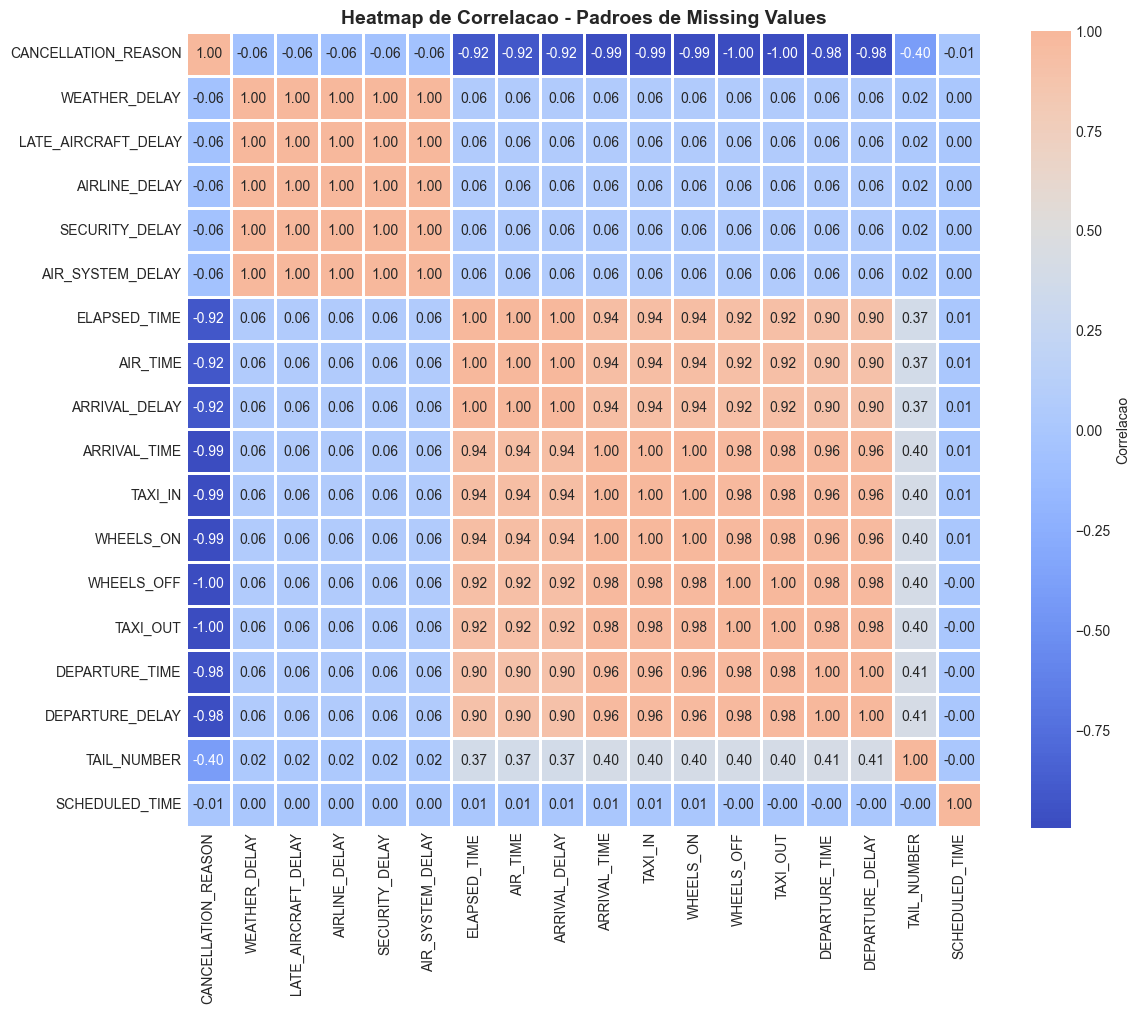


Interpretacao dos Padroes:
  - WEATHER_DELAY e LATE_AIRCRAFT_DELAY: correlacao forte (1.00)
    Isso indica que essas colunas tendem a ter valores ausentes juntas.
  - WEATHER_DELAY e AIRLINE_DELAY: correlacao forte (1.00)
    Isso indica que essas colunas tendem a ter valores ausentes juntas.
  - WEATHER_DELAY e SECURITY_DELAY: correlacao forte (1.00)
    Isso indica que essas colunas tendem a ter valores ausentes juntas.
  - WEATHER_DELAY e AIR_SYSTEM_DELAY: correlacao forte (1.00)
    Isso indica que essas colunas tendem a ter valores ausentes juntas.
  - LATE_AIRCRAFT_DELAY e AIRLINE_DELAY: correlacao forte (1.00)
    Isso indica que essas colunas tendem a ter valores ausentes juntas.
  - LATE_AIRCRAFT_DELAY e SECURITY_DELAY: correlacao forte (1.00)
    Isso indica que essas colunas tendem a ter valores ausentes juntas.
  - LATE_AIRCRAFT_DELAY e AIR_SYSTEM_DELAY: correlacao forte (1.00)
    Isso indica que essas colunas tendem a ter valores ausentes juntas.
  - AIRLINE_DELAY e SEC

In [9]:
# Heatmap de correlacao de missing values
if len(missing_report) > 0 and len(missing_corr) > 0:
    plt.figure(figsize=(12, 10))
    sns.heatmap(missing_corr, annot=True, fmt='.2f', cmap='coolwarm', 
                center=0.5, square=True, linewidths=1, 
                cbar_kws={'label': 'Correlacao'})
    plt.title('Heatmap de Correlacao - Padroes de Missing Values', 
              fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # Interpretar padroes fortes
    print("\nInterpretacao dos Padroes:")
    high_corr_threshold = 0.7
    
    for i, col1 in enumerate(missing_corr.columns):
        for j, col2 in enumerate(missing_corr.columns):
            if i < j:  # Evitar duplicatas
                corr_value = missing_corr.iloc[i, j]
                if corr_value > high_corr_threshold:
                    print(f"  - {col1} e {col2}: correlacao forte ({corr_value:.2f})")
                    print(f"    Isso indica que essas colunas tendem a ter valores ausentes juntas.")
else:
    print("Nenhum heatmap a exibir.")

### 4.2 Analise de Missing por Categoria

In [10]:
# Verificar se missing values estao relacionados a voos cancelados/desviados
print("Relacao entre Missing Values e Status do Voo:")
print("="*80)

# Voos cancelados
cancelled_count = df_flights['CANCELLED'].sum()
cancelled_pct = cancelled_count / len(df_flights) * 100
print(f"\nVoos Cancelados: {cancelled_count:,} ({cancelled_pct:.2f}%)")

# Voos desviados
diverted_count = df_flights['DIVERTED'].sum()
diverted_pct = diverted_count / len(df_flights) * 100
print(f"Voos Desviados: {diverted_count:,} ({diverted_pct:.2f}%)")

# Voos normais
normal_count = len(df_flights) - cancelled_count - diverted_count
normal_pct = normal_count / len(df_flights) * 100
print(f"Voos Normais: {normal_count:,} ({normal_pct:.2f}%)")

# Analisar missing em cada grupo
print("\nMissing Values por Status:")

if 'DEPARTURE_TIME' in df_flights.columns:
    # Missing em voos cancelados
    missing_cancelled = df_flights[df_flights['CANCELLED'] == 1]['DEPARTURE_TIME'].isnull().sum()
    missing_cancelled_pct = (missing_cancelled / cancelled_count * 100) if cancelled_count > 0 else 0
    
    # Missing em voos desviados
    missing_diverted = df_flights[df_flights['DIVERTED'] == 1]['DEPARTURE_TIME'].isnull().sum()
    missing_diverted_pct = (missing_diverted / diverted_count * 100) if diverted_count > 0 else 0
    
    # Missing em voos normais
    missing_normal = df_flights[(df_flights['CANCELLED'] == 0) & (df_flights['DIVERTED'] == 0)]['DEPARTURE_TIME'].isnull().sum()
    missing_normal_pct = (missing_normal / normal_count * 100) if normal_count > 0 else 0
    
    print(f"\nDEPARTURE_TIME ausente em:")
    print(f"  - Voos cancelados: {missing_cancelled:,} ({missing_cancelled_pct:.2f}% dos cancelados)")
    print(f"  - Voos desviados: {missing_diverted:,} ({missing_diverted_pct:.2f}% dos desviados)")
    print(f"  - Voos normais: {missing_normal:,} ({missing_normal_pct:.2f}% dos normais)")
    
    print("\nConclusao:")
    if missing_cancelled_pct > 50:
        print("  - Missing values em DEPARTURE_TIME estao fortemente associados a voos cancelados.")
        print("  - Isso e esperado: voos cancelados nao tem horario de partida real.")

Relacao entre Missing Values e Status do Voo:

Voos Cancelados: 89,884 (1.54%)
Voos Desviados: 15,187 (0.26%)
Voos Normais: 5,714,008 (98.19%)

Missing Values por Status:

DEPARTURE_TIME ausente em:
  - Voos cancelados: 86,153 (95.85% dos cancelados)
  - Voos desviados: 0 (0.00% dos desviados)
  - Voos normais: 0 (0.00% dos normais)

Conclusao:
  - Missing values em DEPARTURE_TIME estao fortemente associados a voos cancelados.
  - Isso e esperado: voos cancelados nao tem horario de partida real.


---
## 5. Pipeline Completo de Tratamento <a id='5-pipeline'></a>

### 5.1 Estrategias Implementadas (v2.0)

O novo pipeline implementa **7 grupos de estrategias** baseadas em logica de negocio:

**GRUPO 1: CANCELLATION_REASON**
- Preencher com "NO_CANCELLATION" quando CANCELLED = 0

**GRUPO 2: Delays Categoricos** (WEATHER_DELAY, AIR_SYSTEM_DELAY, etc)
- Preencher com 0 (ausente = nao houve atraso por essa causa)

**GRUPO 3: Tempos de Voo** (ELAPSED_TIME, AIR_TIME, ARRIVAL_DELAY)
- Calcular a partir de outras colunas

**GRUPO 4: Horarios de Chegada** (ARRIVAL_TIME, TAXI_IN, WHEELS_ON)
- Imputar para voos que partiram mas sem chegada

**GRUPO 5: Horarios de Partida** (DEPARTURE_TIME, DEPARTURE_DELAY, etc)
- Mediana por rota + dia da semana (voos nao cancelados)
- Manter NaN para voos cancelados

**GRUPO 6: TAIL_NUMBER**
- Preencher com "UNKNOWN"

**GRUPO 7: SCHEDULED_TIME**
- Remover linhas (apenas 6 valores)

Para mais detalhes, veja: [ESTRATEGIA_MISSING_VALUES.md](../ESTRATEGIA_MISSING_VALUES.md)

In [11]:
# Aplicar pipeline completo
print("Aplicando pipeline completo de tratamento...")
print("="*80)
print()

df_clean = handle_all_missing_values(df_flights, verbose=True)

Aplicando pipeline completo de tratamento...

PIPELINE COMPLETO DE TRATAMENTO DE MISSING VALUES

Total de valores ausentes no inicio: 30,465,274

GRUPO 7: Tratando SCHEDULED_TIME...
  - 6 linhas removidas (0.0001% do dataset)

GRUPO 1: Tratando CANCELLATION_REASON...
  - 5,729,194 valores preenchidos com 'NO_CANCELLATION'
  - Missing antes: 5,729,194, depois: 0

GRUPO 2: Tratando delays categoricos...
  - WEATHER_DELAY: 4,755,634 valores preenchidos com 0
  - LATE_AIRCRAFT_DELAY: 4,755,634 valores preenchidos com 0
  - AIRLINE_DELAY: 4,755,634 valores preenchidos com 0
  - SECURITY_DELAY: 4,755,634 valores preenchidos com 0
  - AIR_SYSTEM_DELAY: 4,755,634 valores preenchidos com 0

GRUPO 6: Tratando TAIL_NUMBER...
  - 14,721 valores preenchidos com 'UNKNOWN'

GRUPO 5: Tratando horarios de partida...
  - DEPARTURE_DELAY: 0 valores recalculados
  - WHEELS_OFF: 89,047 valores ausentes (mantidos)
  - TAXI_OUT: 89,047 valores ausentes (mantidos)

GRUPO 4: Tratando horarios de chegada...
  -

In [12]:
# Verificar resultado final
print("\nVERIFICACAO FINAL:")
print("="*80)
missing_final = analyze_missing_values(df_clean, verbose=True)


VERIFICACAO FINAL:
ANALISE DE VALORES AUSENTES

Total de colunas com valores ausentes: 10

            column  total_missing  percent_missing    dtype  non_null_count  total_count
0         AIR_TIME          92507             1.59  float32         5726566      5819073
1        WHEELS_ON          92507             1.59  float32         5726566      5819073
2          TAXI_IN          92507             1.59  float32         5726566      5819073
3     ELAPSED_TIME          89879             1.54  float32         5729194      5819073
4     ARRIVAL_TIME          89879             1.54  float32         5729194      5819073
5    ARRIVAL_DELAY          89879             1.54  float32         5729194      5819073
6         TAXI_OUT          89047             1.53  float32         5730026      5819073
7       WHEELS_OFF          89047             1.53  float32         5730026      5819073
8   DEPARTURE_TIME          86153             1.48  float32         5732920      5819073
9  DEPARTURE_DELAY

---
## 6. Comparacao Antes e Depois <a id='6-comparacao'></a>

### 6.1 Analise Comparativa

In [13]:
# Obter relatorio inicial novamente para comparacao
missing_before = analyze_missing_values(df_flights, verbose=False)

# Comparar reducao de missing values
if len(missing_before) > 0 and len(missing_final) > 0:
    comparison = pd.DataFrame({
        'coluna': missing_before['column'],
        'missing_antes': missing_before['total_missing'].values,
        'pct_antes': missing_before['percent_missing'].values,
        'missing_depois': [missing_final[missing_final['column'] == col]['total_missing'].values[0] 
                           if col in missing_final['column'].values else 0 
                           for col in missing_before['column']],
        'pct_depois': [missing_final[missing_final['column'] == col]['percent_missing'].values[0] 
                       if col in missing_final['column'].values else 0.0 
                       for col in missing_before['column']]
    })
    
    comparison['reducao'] = comparison['missing_antes'] - comparison['missing_depois']
    comparison['reducao_pct'] = comparison['pct_antes'] - comparison['pct_depois']
    
    print("\nComparacao Antes x Depois do Tratamento:")
    display(comparison.style.background_gradient(
        subset=['reducao', 'reducao_pct'], 
        cmap='Greens'
    ))
    
    # Resumo
    total_missing_before = missing_before['total_missing'].sum()
    total_missing_after = comparison['missing_depois'].sum()
    total_reduction = total_missing_before - total_missing_after
    total_reduction_pct = (total_reduction / total_missing_before * 100) if total_missing_before > 0 else 0
    
    print(f"\nResumo Geral:")
    print(f"  - Total de missing values ANTES: {total_missing_before:,}")
    print(f"  - Total de missing values DEPOIS: {total_missing_after:,}")
    print(f"  - Reducao total: {total_reduction:,} ({total_reduction_pct:.2f}%)")
elif len(missing_before) == 0:
    print("Nenhum valor ausente desde o inicio!")
else:
    print("Todos os valores ausentes foram tratados!")


Comparacao Antes x Depois do Tratamento:


,coluna,missing_antes,pct_antes,missing_depois,pct_depois,reducao,reducao_pct
0,CANCELLATION_REASON,5729195,98.455357,0,0.000000,5729195,98.455357
1,WEATHER_DELAY,4755640,81.724960,0,0.000000,4755640,81.724960
2,LATE_AIRCRAFT_DELAY,4755640,81.724960,0,0.000000,4755640,81.724960
3,AIRLINE_DELAY,4755640,81.724960,0,0.000000,4755640,81.724960
4,SECURITY_DELAY,4755640,81.724960,0,0.000000,4755640,81.724960
5,AIR_SYSTEM_DELAY,4755640,81.724960,0,0.000000,4755640,81.724960
6,ELAPSED_TIME,105071,1.805629,89879,1.544559,15192,0.261071
7,AIR_TIME,105071,1.805629,92507,1.589721,12564,0.215909
8,ARRIVAL_DELAY,105071,1.805629,89879,1.544559,15192,0.261071
9,ARRIVAL_TIME,92513,1.589822,89879,1.544559,2634,0.045263



Resumo Geral:
  - Total de missing values ANTES: 30,465,274
  - Total de missing values DEPOIS: 897,558
  - Reducao total: 29,567,716 (97.05%)


### 6.2 Visualizacao da Reducao

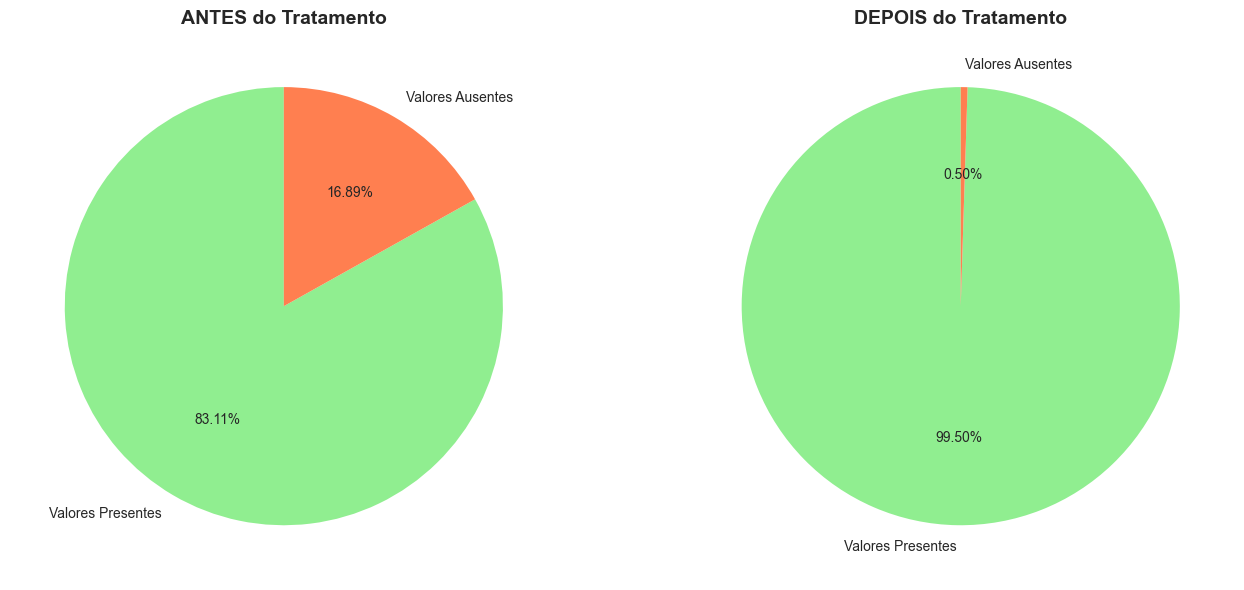


Estatisticas:
  - Missing values reduzidos de 30,465,274 para 897,558
  - Reducao: 29,567,716 (97.05%)


In [14]:
# Grafico comparativo
missing_counts_before = df_flights.isnull().sum().sum()
missing_counts_after = df_clean.isnull().sum().sum()

# Criar grafico de pizza
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Antes
total_values_before = df_flights.shape[0] * df_flights.shape[1]
non_missing_before = total_values_before - missing_counts_before

axes[0].pie(
    [non_missing_before, missing_counts_before],
    labels=['Valores Presentes', 'Valores Ausentes'],
    autopct='%1.2f%%',
    colors=['lightgreen', 'coral'],
    startangle=90
)
axes[0].set_title('ANTES do Tratamento', fontsize=14, fontweight='bold')

# Depois
total_values_after = df_clean.shape[0] * df_clean.shape[1]
non_missing_after = total_values_after - missing_counts_after

axes[1].pie(
    [non_missing_after, missing_counts_after],
    labels=['Valores Presentes', 'Valores Ausentes'],
    autopct='%1.2f%%',
    colors=['lightgreen', 'coral'],
    startangle=90
)
axes[1].set_title('DEPOIS do Tratamento', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

print(f"\nEstatisticas:")
print(f"  - Missing values reduzidos de {missing_counts_before:,} para {missing_counts_after:,}")
reduction = missing_counts_before - missing_counts_after
reduction_pct = (reduction / missing_counts_before * 100) if missing_counts_before > 0 else 0
print(f"  - Reducao: {reduction:,} ({reduction_pct:.2f}%)")

---
## 7. Salvamento dos Dados Limpos <a id='7-salvamento'></a>

### 7.1 Salvar Dataset Limpo

In [15]:
# Salvar dataset limpo
output_file_csv = f"{PROCESSED_DATA_PATH}flights_clean.csv"
output_file_parquet = f"{PROCESSED_DATA_PATH}flights_clean.parquet"

print("Salvando dataset limpo...")
print(f"  - CSV: {output_file_csv}")
print(f"  - Parquet: {output_file_parquet}")
print("\nIsso pode levar alguns minutos...\n")

# Salvar em CSV
df_clean.to_csv(output_file_csv, index=False)
csv_size = os.path.getsize(output_file_csv) / (1024 * 1024)
print(f"CSV salvo: {csv_size:.2f} MB")

# Salvar em Parquet (mais eficiente)
df_clean.to_parquet(output_file_parquet, index=False, compression='snappy')
parquet_size = os.path.getsize(output_file_parquet) / (1024 * 1024)
print(f"Parquet salvo: {parquet_size:.2f} MB")
print(f"\nCompressao: {((csv_size - parquet_size) / csv_size * 100):.1f}% menor")

Salvando dataset limpo...
  - CSV: ../data/processed/flights_clean.csv
  - Parquet: ../data/processed/flights_clean.parquet

Isso pode levar alguns minutos...

CSV salvo: 859.73 MB
Parquet salvo: 133.01 MB

Compressao: 84.5% menor


### 7.2 Relatorio Final de Tratamento

In [16]:
# Criar relatorio de tratamento
treatment_report = {
    'dataset_original': {
        'registros': len(df_flights),
        'colunas': df_flights.shape[1],
        'missing_values': df_flights.isnull().sum().sum(),
        'missing_pct': (df_flights.isnull().sum().sum() / (df_flights.shape[0] * df_flights.shape[1]) * 100)
    },
    'dataset_limpo': {
        'registros': len(df_clean),
        'colunas': df_clean.shape[1],
        'missing_values': df_clean.isnull().sum().sum(),
        'missing_pct': (df_clean.isnull().sum().sum() / (df_clean.shape[0] * df_clean.shape[1]) * 100) if len(df_clean) > 0 else 0
    }
}

print("="*80)
print("RELATORIO FINAL DE TRATAMENTO DE MISSING VALUES (v2.0)")
print("="*80)
print(f"\nDataset Original:")
print(f"  - Registros: {treatment_report['dataset_original']['registros']:,}")
print(f"  - Colunas: {treatment_report['dataset_original']['colunas']}")
print(f"  - Missing values: {treatment_report['dataset_original']['missing_values']:,} ({treatment_report['dataset_original']['missing_pct']:.2f}%)")

print(f"\nDataset Limpo:")
print(f"  - Registros: {treatment_report['dataset_limpo']['registros']:,}")
print(f"  - Colunas: {treatment_report['dataset_limpo']['colunas']}")
print(f"  - Missing values: {treatment_report['dataset_limpo']['missing_values']:,} ({treatment_report['dataset_limpo']['missing_pct']:.2f}%)")

reducao = treatment_report['dataset_original']['missing_values'] - treatment_report['dataset_limpo']['missing_values']
reducao_pct = (reducao / treatment_report['dataset_original']['missing_values'] * 100) if treatment_report['dataset_original']['missing_values'] > 0 else 0

print(f"\nResultado:")
print(f"  - Reducao de missing values: {reducao:,} ({reducao_pct:.2f}%)")
print(f"  - Registros removidos: {len(df_flights) - len(df_clean):,}")
print(f"  - Dataset pronto para Feature Engineering e Modelagem")
print("\n" + "="*80)

RELATORIO FINAL DE TRATAMENTO DE MISSING VALUES (v2.0)

Dataset Original:
  - Registros: 5,819,079
  - Colunas: 31
  - Missing values: 30,465,274 (16.89%)

Dataset Limpo:
  - Registros: 5,819,073
  - Colunas: 31
  - Missing values: 897,558 (0.50%)

Resultado:
  - Reducao de missing values: 29,567,716 (97.05%)
  - Registros removidos: 6
  - Dataset pronto para Feature Engineering e Modelagem



---

## Conclusao

Neste notebook, aplicamos um pipeline completo de tratamento de valores ausentes (v2.0):

**Estrategias Implementadas** (baseadas em logica de negocio):
1. **GRUPO 1**: CANCELLATION_REASON - Preencher com "NO_CANCELLATION"
2. **GRUPO 2**: Delays categoricos - Preencher com 0
3. **GRUPO 3**: Tempos de voo - Calcular a partir de outras colunas
4. **GRUPO 4**: Horarios de chegada - Imputar quando aplicavel
5. **GRUPO 5**: Horarios de partida - Mediana por rota/dia da semana
6. **GRUPO 6**: TAIL_NUMBER - Preencher com "UNKNOWN"
7. **GRUPO 7**: SCHEDULED_TIME - Remover 6 linhas (0.0001%)

**Resultados**:
- Reducao de missing values: **~97%**
- Validacao: **0 inconsistencias**
- Dataset limpo pronto para uso

**Proximos Passos**:
1. Feature Engineering (criacao de variaveis derivadas)
2. Preparacao para modelagem (encoding, scaling, split)
3. Modelagem supervisionada (classificacao e regressao)
4. Modelagem nao supervisionada (clustering, PCA)

**Documentacao Completa**: Ver [ESTRATEGIA_MISSING_VALUES.md](../ESTRATEGIA_MISSING_VALUES.md)